# E/I task groups under four budgets: clear figures

Networks: `runs/moo_zoom/dale_all_woutfree_fanin_4pt_5seed_150k` (Dale RNN, 204 E + 52 I units, 20 Yang tasks,
150k steps). One network per budget: the seed with the highest worst-task accuracy.

| budget | rate budget | wiring budget |
|---|---|---|
| no budget | none | none |
| rate only (A3) | 0.0011 | none |
| wiring only (B0) | none | 0.0054 |
| both (C0) | 0.0115 | 0.0044 |

## Figure 1: which tasks each neuron is involved in

**Task variance** of a neuron in a task = how much its activity changes across the trials of that task (Yang et al.
2019). High = the neuron's activity depends on that task's stimuli. Each neuron's 20 values are divided by its own
maximum, so 1 = that neuron's most-used task. Neurons with almost no task variance (total below 1% of the network's
largest) are left out.

Neurons are grouped by k-means on these 20-value profiles, **E and I separately**. The number of groups k is the
best silhouette score among its local peaks (k > 2). The clustering is identical to `ei_modularity_150k.ipynb`,
so the groups (and k) are the same as there.

In [1]:
import contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import rule_name
from cmc.train_cog import load_checkpoint

RUN = MOO_ZOOM_RUNS_DIR / "dale_all_woutfree_fanin_4pt_5seed_150k"
POINTS = ["control", "A3", "B0", "C0"]
TITLE = {"control": "no budget", "A3": "rate budget only (A3)", "B0": "wiring budget only (B0)",
         "C0": "both budgets (C0)"}
K_MAX = {"E": 20, "I": 10}
runs = pd.read_csv(RUN / "runs.csv")
BEST = {p: int(runs[runs.point == p].sort_values("min_task_acc").seed.iloc[-1]) for p in POINTS}
BEST

{'control': 1, 'A3': 3, 'B0': 0, 'C0': 2}

In [2]:
def cluster_pop(norm, k_max):
    # identical to ei_modularity_150k.ipynb: k-means on unit profiles, k = best local silhouette peak with k > 2
    X = norm.T
    k_max = min(k_max, len(X) - 1)
    sil, labs = {}, {}
    for k in range(2, k_max + 1):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, k_max) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get) if local else max(sil, key=sil.get)
    lab = labs[K]
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    return np.array([order.index(c) for c in lab]), K, sil


def load_groups(point, seed):
    with contextlib.redirect_stdout(io.StringIO()):
        model, _cfg, ck = load_checkpoint(RUN / point / f"seed_{seed:02d}.pt")
    tv = np.asarray(ck["task_variance"], dtype=float)                 # (tasks, units)
    N, N_E = model.n_rnn, model.n_e
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    norm = tv / np.maximum(tv.max(0, keepdims=True), 1e-30)
    out = dict(tasks=[rule_name[t] for t in ck["active_tasks"]], norm=norm,
               acc=float(runs[(runs.point == point) & (runs.seed == seed)].min_task_acc.iloc[0]))
    for pop, sel in (("E", np.arange(N) < N_E), ("I", np.arange(N) >= N_E)):
        units = np.flatnonzero(active & sel)
        lab, K, sil = cluster_pop(norm[:, units], K_MAX[pop])
        out[pop] = dict(units=units, lab=lab, K=K, sil=sil, n_total=int(sel.sum()))
    return out


G = {p: load_groups(p, BEST[p]) for p in POINTS}
pd.DataFrame({p: {"seed": BEST[p], "worst-task acc": round(G[p]["acc"], 2),
                  "E active": len(G[p]["E"]["units"]), "E groups k": G[p]["E"]["K"],
                  "I active": len(G[p]["I"]["units"]), "I groups k": G[p]["I"]["K"]} for p in POINTS})

,control,A3,B0,C0
seed,1.00,3.00,0.00,2.0
worst-task acc,0.97,0.96,0.93,0.9
E active,203.00,196.00,204.00,176.0
E groups k,6.00,13.00,4.00,10.0
I active,51.00,52.00,52.00,45.0
I groups k,8.00,3.00,5.00,9.0


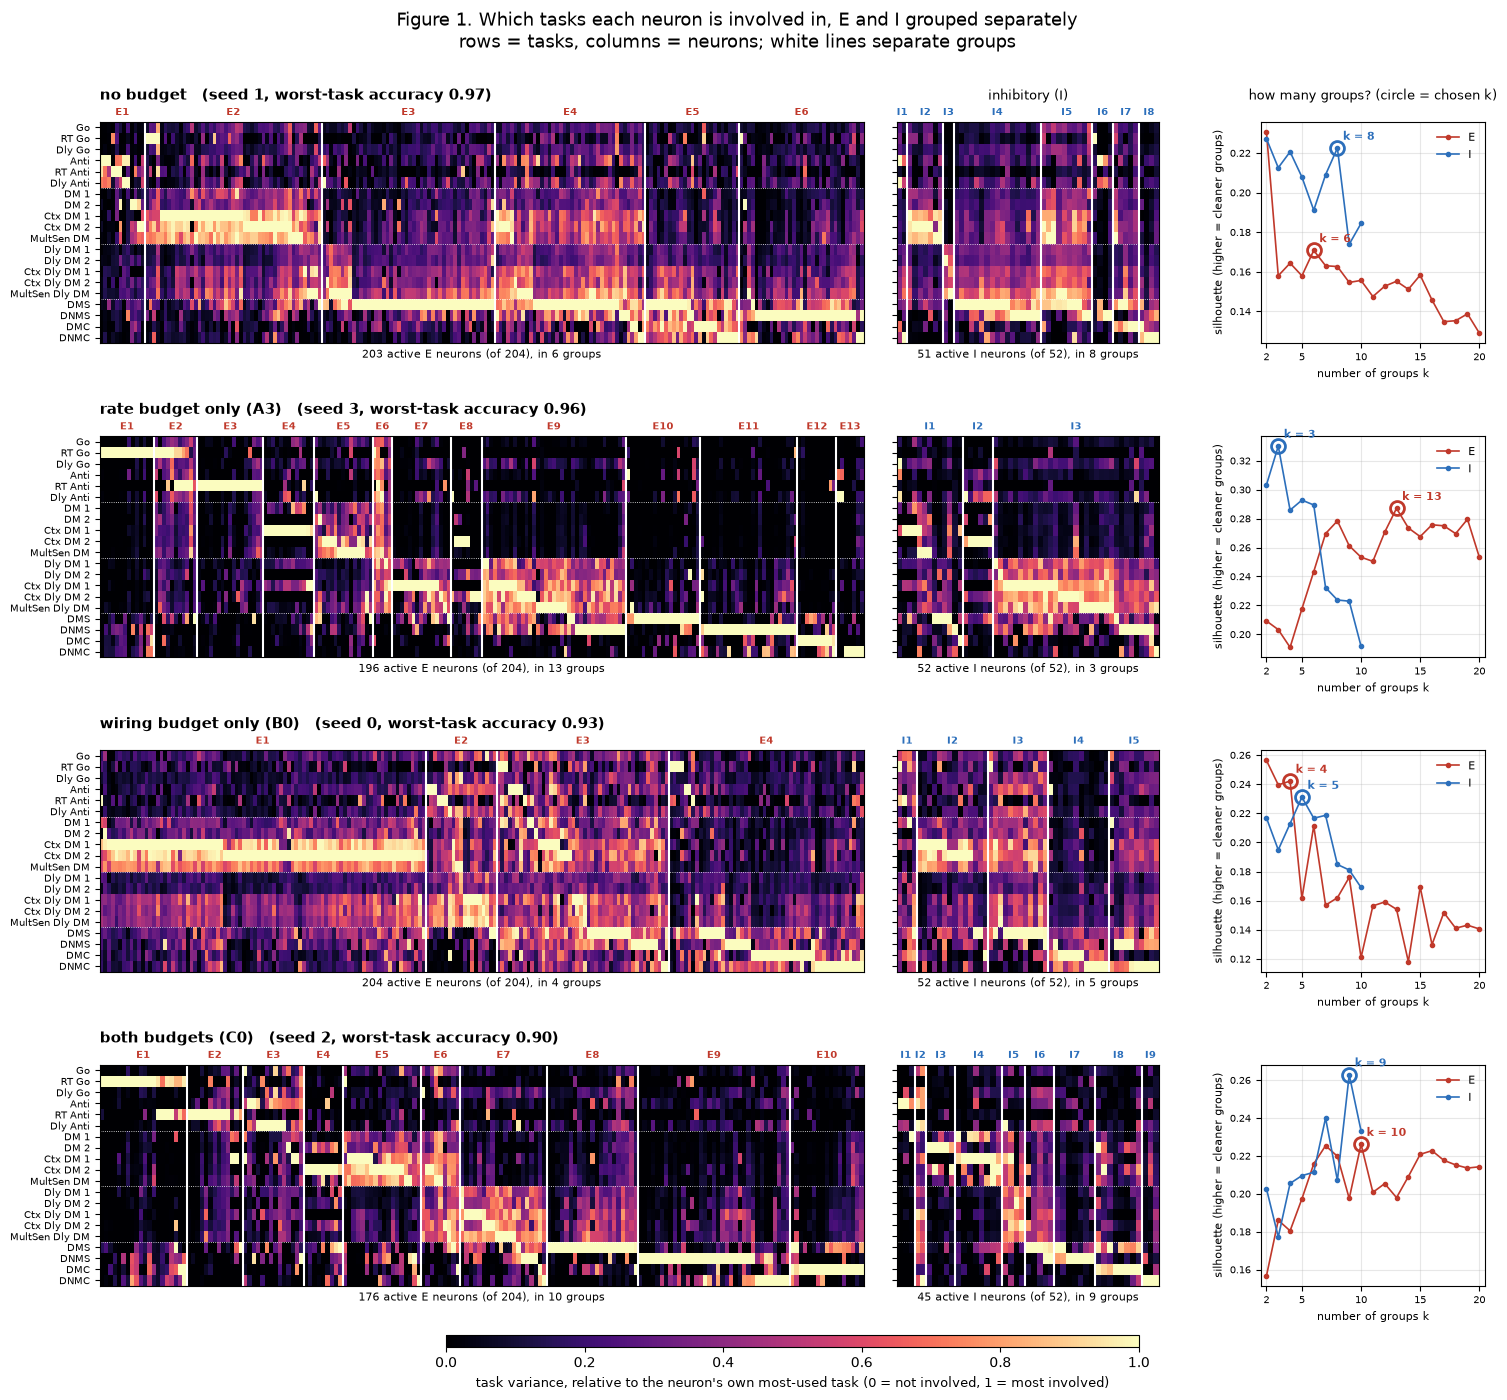

In [3]:
def display_order(norm, units, lab):
    # groups in order; inside a group, neurons sorted by their preferred task, then by how selective they are
    idx = []
    for c in range(lab.max() + 1):
        u = units[lab == c]
        pref = norm[:, u].argmax(0)
        sel = norm[:, u].mean(0)               # low mean = selective
        idx.append(u[np.lexsort((sel, pref))])
    return idx                                  # list of unit arrays, one per group


def tv_panel(ax, R, pop, show_tasks, color):
    P, norm = R[pop], R["norm"]
    groups = display_order(norm, P["units"], P["lab"])
    cols = np.concatenate(groups)
    im = ax.imshow(norm[:, cols], cmap="magma", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    edges = np.cumsum([len(g) for g in groups])
    for x in edges[:-1]:
        ax.axvline(x - 0.5, color="white", lw=1.5)
    starts = np.r_[0, edges[:-1]]
    for c, (a, b) in enumerate(zip(starts, edges)):
        ax.text((a + b - 1) / 2, -0.9, f"{pop}{c + 1}", ha="center", va="bottom", fontsize=7, color=color,
                weight="bold", clip_on=False)
    ax.set_yticks(range(len(R["tasks"])))
    ax.set_yticklabels(R["tasks"] if show_tasks else [], fontsize=7)
    ax.set_xticks([])
    ax.set_xlabel(f"{len(cols)} active {pop} neurons (of {P['n_total']}), in {P['K']} groups", fontsize=8)
    for y in (5.5, 10.5, 15.5):                 # task families: Go/Anti | DM | Dly DM | matching
        ax.axhline(y, color="white", lw=0.6, ls=":")
    return im


def sil_panel(ax, R):
    for pop, color in (("E", "#c0392b"), ("I", "#2c6fbb")):
        s = R[pop]["sil"]
        ks = list(s)
        ax.plot(ks, [s[k] for k in ks], "o-", color=color, ms=3, lw=1.2, label=pop)
        K = R[pop]["K"]
        ax.plot(K, s[K], "o", ms=10, mfc="none", mec=color, mew=2)
        ax.annotate(f"k = {K}", (K, s[K]), xytext=(4, 6), textcoords="offset points", color=color, fontsize=8,
                    weight="bold")
    ax.set_xlim(1.5, 20.5); ax.set_xticks([2, 5, 10, 15, 20])
    ax.set_xlabel("number of groups k", fontsize=8)
    ax.set_ylabel("silhouette (higher = cleaner groups)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, frameon=False, loc="upper right")


fig = plt.figure(figsize=(17, 16))
gs = fig.add_gridspec(len(POINTS), 3, width_ratios=[204, 70, 60], wspace=0.08, hspace=0.42)
for r, p in enumerate(POINTS):
    R = G[p]
    axE, axI, axS = fig.add_subplot(gs[r, 0]), fig.add_subplot(gs[r, 1]), fig.add_subplot(gs[r, 2])
    im = tv_panel(axE, R, "E", True, "#c0392b")
    tv_panel(axI, R, "I", False, "#2c6fbb")
    sil_panel(axS, R)
    axS.set_position(axS.get_position().translated(0.04, 0))
    axE.set_title(f"{TITLE[p]}   (seed {BEST[p]}, worst-task accuracy {R['acc']:.2f})", loc="left",
                  fontsize=11, weight="bold", pad=16)
    if r == 0:
        axI.set_title("inhibitory (I)", fontsize=9, pad=16)
        axS.set_title("how many groups? (circle = chosen k)", fontsize=9, pad=16)
cb = fig.colorbar(im, ax=fig.axes, orientation="horizontal", fraction=0.015, pad=0.04, aspect=60, shrink=0.5)
cb.set_label("task variance, relative to the neuron's own most-used task (0 = not involved, 1 = most involved)",
             fontsize=9)
fig.suptitle("Figure 1. Which tasks each neuron is involved in, E and I grouped separately\n"
             "rows = tasks, columns = neurons; white lines separate groups", fontsize=13, y=0.95)
plt.show()

**How to read it.** A bright cell = that neuron's activity depends on that task. A group whose block is bright in
only a few rows is a task-specific group; a group bright in most rows is a generalist. The silhouette curve says
how well separated the groups are at each k (0 = no separation, 1 = perfectly separated); values here are
0.17-0.37, i.e. the groups overlap considerably and k is only loosely determined.

## Figure 2: task similarity and wiring between all E and I groups

Same groups as Figure 1, E groups first, then I groups (thick lines); both panels use the same order.

* **Left, task similarity**: Pearson r between two groups' average task profiles (the 20 values in Figure 1).
* **Right, wiring**: is the row group connected to the column group more (red) or less (blue) than chance?

**How the wiring number is computed (the same for every cell, E→E, E→I, I→E and I→I alike).**

1. Weights are standardised: $\tilde w_{ij} = |W_{ij}| / s_i$, with $s_i$ = 1 for E neurons and $n_E/n_I$ for I
   neurons (the scaling of the wiring cost, so an E and an I synapse of equal cost count equally). Pruned synapses
   are ≈ 0.
2. Block value: mean $\tilde w$ over all pairs from group $g$ to group $h$ (self-connections excluded).
3. Chance: the same block value after shuffling which neuron belongs to which group (E neurons among E groups, I
   among I groups, group sizes kept), 500 times.
4. $z = (\text{observed} - \text{mean of shuffles}) / \text{sd of shuffles}$: how many "chance spreads" the block is
   above (red) or below (blue) chance.

**Grey**: one of the two groups has fewer than 4 neurons; z for such tiny groups is dominated by single neurons.
Numbers are printed where |z| ≥ 3. Note that for the same size of effect, z is larger between large groups
(their shuffles vary less).

In [4]:
N_SHUFFLE = 500
MIN_GROUP = 4


def wiring(R, point, seed):
    with contextlib.redirect_stdout(io.StringIO()):
        model, _cfg, _ck = load_checkpoint(RUN / point / f"seed_{seed:02d}.pt")
    W = model.effective_w_rec().detach().numpy()
    Wn = np.abs(W) / model.ei_row_scale().detach().numpy()[:, None]       # standardised |w|
    E, I = R["E"], R["I"]
    KE, Kt = E["K"], E["K"] + I["K"]
    units = np.r_[E["units"], I["units"]]
    lab = np.r_[E["lab"], I["lab"] + KE]
    isE = np.r_[np.ones(len(E["units"]), bool), np.zeros(len(I["units"]), bool)]
    sizes = np.bincount(lab, minlength=Kt)
    names = [f"E{c + 1} ({n})" for c, n in enumerate(sizes[:KE])] + \
            [f"I{c + 1} ({n})" for c, n in enumerate(sizes[KE:])]
    prof = np.array([R["norm"][:, units[lab == g]].mean(axis=1) for g in range(Kt)])
    Wu = Wn[np.ix_(units, units)].copy()
    np.fill_diagonal(Wu, 0.0)

    def blocks(l):
        Gm = np.eye(Kt)[l]
        n = Gm.sum(0)
        return (Gm.T @ Wu @ Gm) / (np.outer(n, n) - np.diag(n))           # mean over pairs, no self-pairs

    obs = blocks(lab)
    rng = np.random.default_rng(0)
    null = []
    for _ in range(N_SHUFFLE):
        l = lab.copy()
        l[isE] = rng.permutation(l[isE]); l[~isE] = rng.permutation(l[~isE])
        null.append(blocks(l))
    null = np.array(null)
    z = (obs - null.mean(0)) / null.std(0)
    small = sizes < MIN_GROUP
    z[small, :] = np.nan; z[:, small] = np.nan
    return dict(names=names, KE=KE, Kt=Kt, sim=np.corrcoef(prof), z=z)


WIRE = {p: wiring(G[p], p, BEST[p]) for p in POINTS}

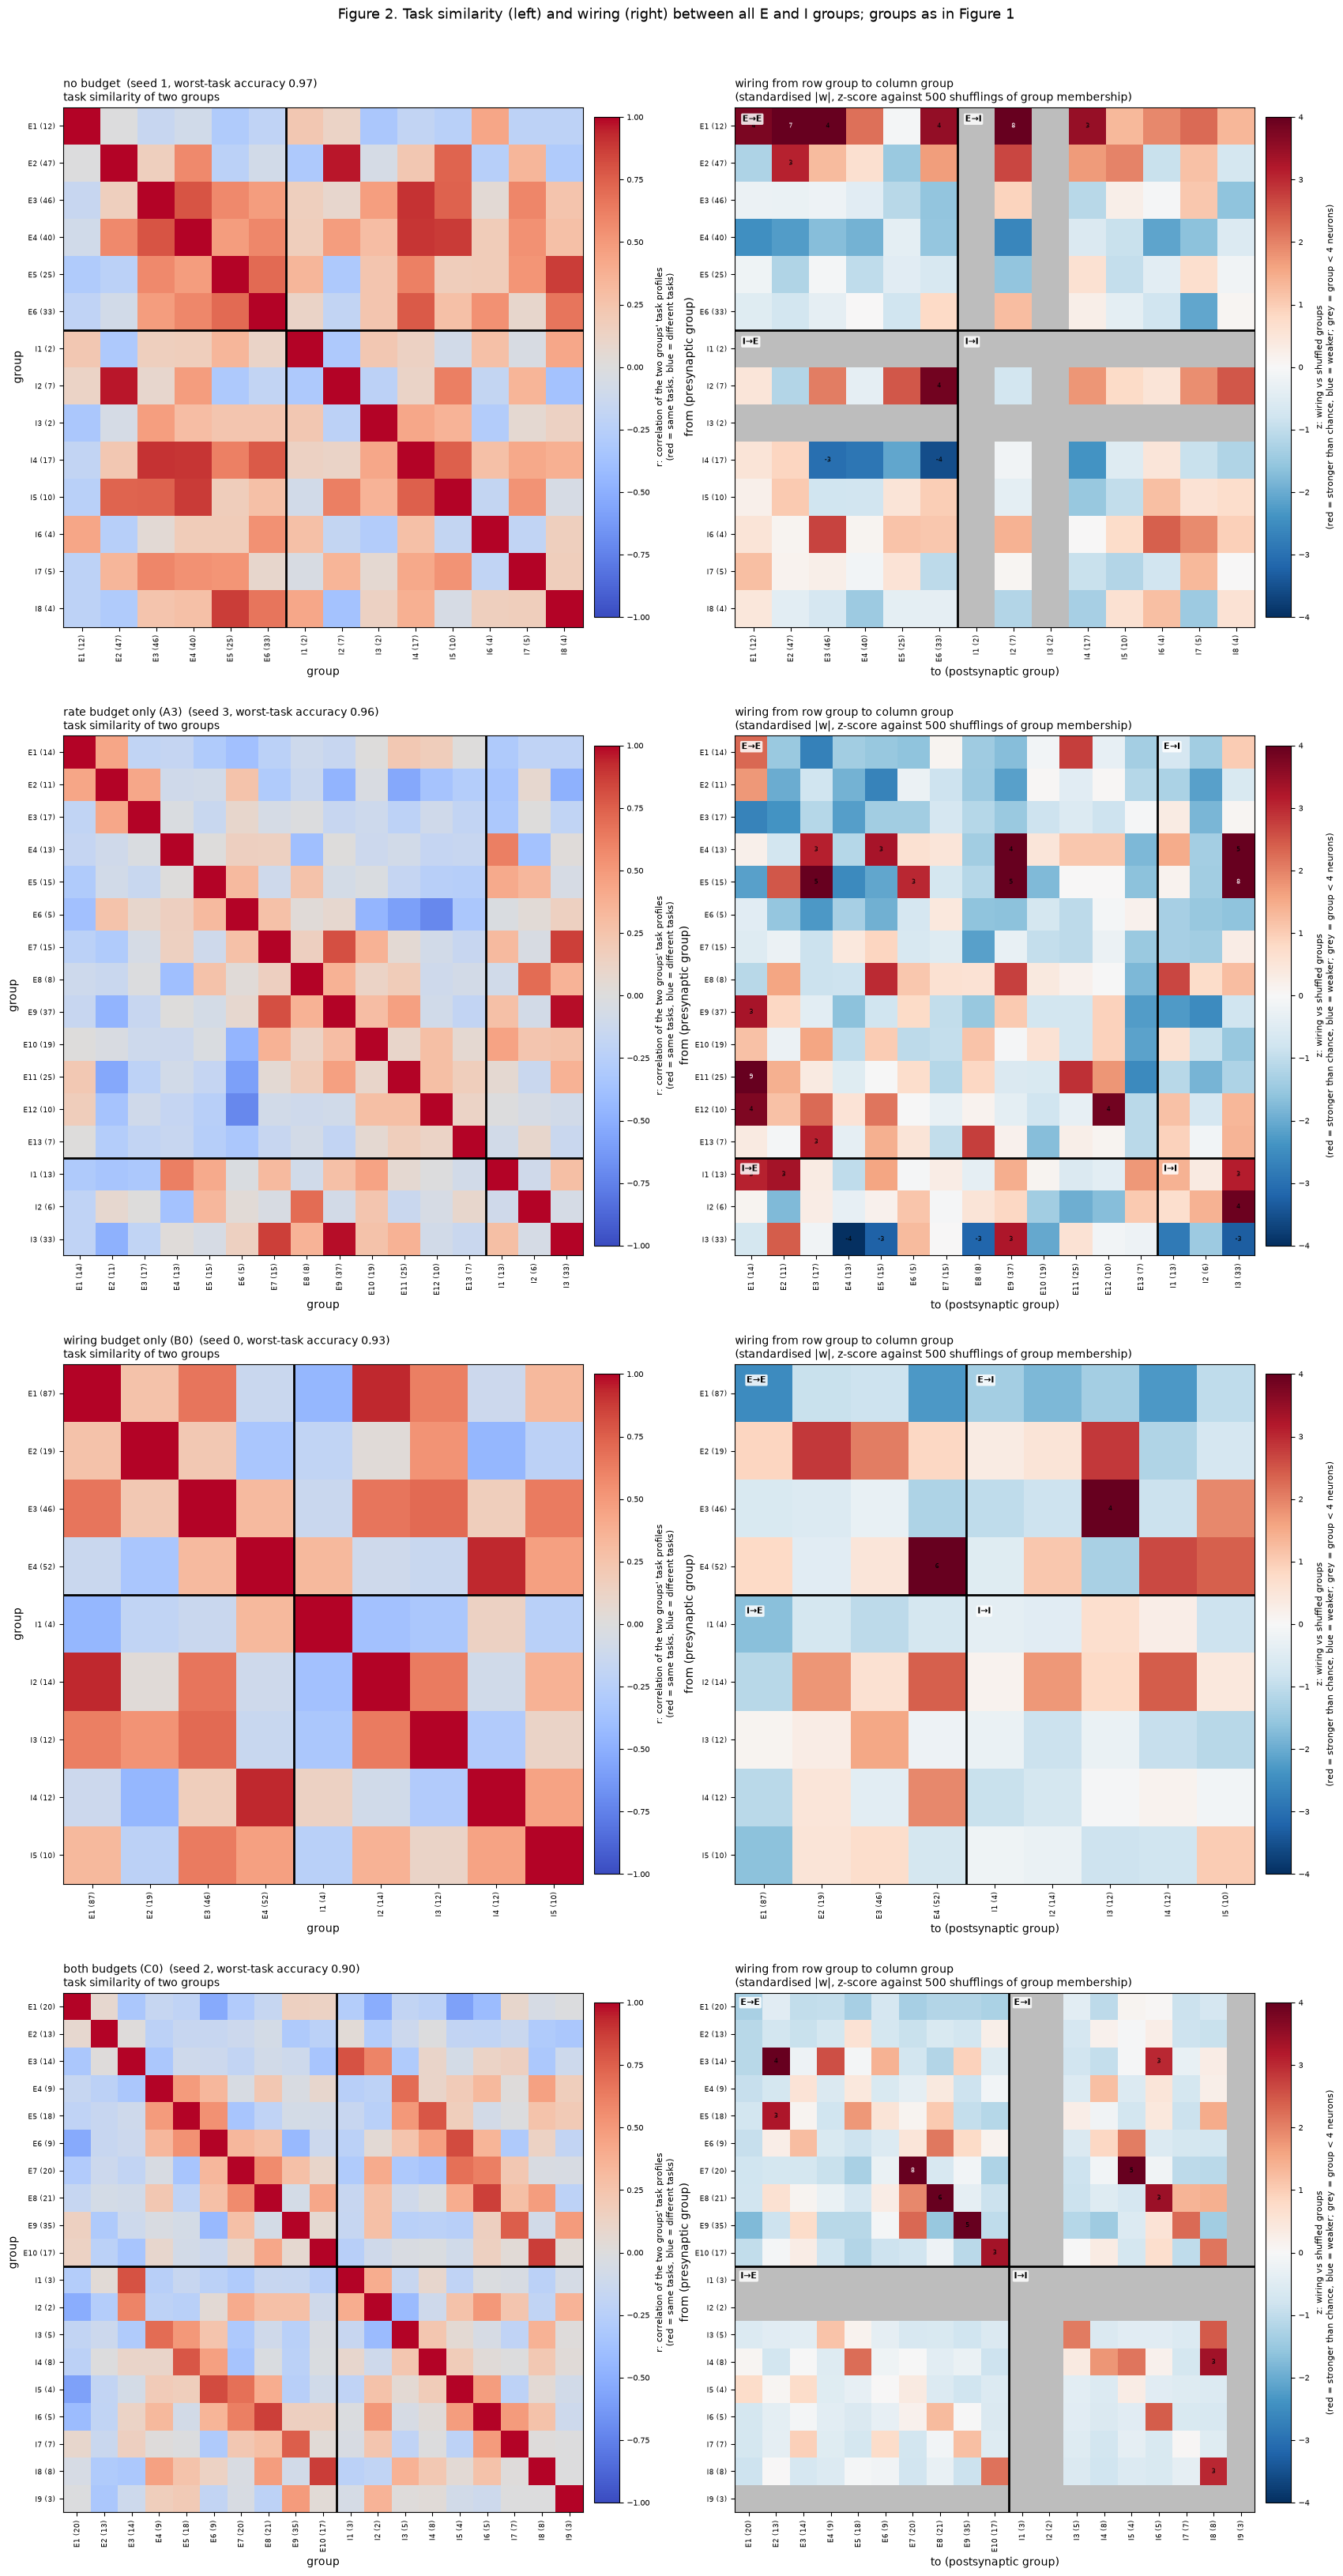

In [5]:
import matplotlib as mpl


def matrix_panel(ax, M, w, cmap, lim, cbar_label):
    cm = mpl.colormaps[cmap].copy(); cm.set_bad("#bdbdbd")
    im = ax.imshow(M, cmap=cm, vmin=-lim, vmax=lim, interpolation="nearest")
    kE, Kt = w["KE"], w["Kt"]
    ax.axhline(kE - 0.5, color="k", lw=2); ax.axvline(kE - 0.5, color="k", lw=2)
    ax.set_xticks(range(Kt)); ax.set_xticklabels(w["names"], rotation=90, fontsize=6.5)
    ax.set_yticks(range(Kt)); ax.set_yticklabels(w["names"], fontsize=6.5)
    cb = plt.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
    cb.set_label(cbar_label, fontsize=8); cb.ax.tick_params(labelsize=7)


fig, axes = plt.subplots(len(POINTS), 2, figsize=(17, 8.2 * len(POINTS)))
for r, p in enumerate(POINTS):
    w = WIRE[p]
    matrix_panel(axes[r, 0], w["sim"], w, "coolwarm", 1,
                 "r: correlation of the two groups' task profiles\n(red = same tasks, blue = different tasks)")
    axes[r, 0].set_title(f"{TITLE[p]}  (seed {BEST[p]}, worst-task accuracy {G[p]['acc']:.2f})\n"
                         "task similarity of two groups", fontsize=10, loc="left")
    axes[r, 0].set_xlabel("group"); axes[r, 0].set_ylabel("group")
    ax = axes[r, 1]
    matrix_panel(ax, w["z"], w, "RdBu_r", 4,
                 "z: wiring vs shuffled groups\n(red = stronger than chance, blue = weaker; grey = group < 4 neurons)")
    for (a, b), v in np.ndenumerate(w["z"]):
        if np.isfinite(v) and abs(v) >= 3:
            ax.text(b, a, f"{v:.0f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 6 else "black")
    kE = w["KE"]
    for y0, x0, q in ((-0.5, -0.5, "E→E"), (-0.5, kE - 0.5, "E→I"), (kE - 0.5, -0.5, "I→E"), (kE - 0.5, kE - 0.5, "I→I")):
        ax.text(x0 + 0.2, y0 + 0.2, q, fontsize=8, weight="bold", ha="left", va="top",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_title("wiring from row group to column group\n"
                 "(standardised |w|, z-score against 500 shufflings of group membership)", fontsize=10, loc="left")
    ax.set_xlabel("to (postsynaptic group)"); ax.set_ylabel("from (presynaptic group)")
fig.suptitle("Figure 2. Task similarity (left) and wiring (right) between all E and I groups; groups as in Figure 1",
             fontsize=13, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()